<a href="https://colab.research.google.com/github/simon-clematide/colab-notebooks-for-teaching/blob/main/openai_word_embeddings_apps.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Understanding Multilingual Word Embeddings

This notebook introduces the basic concepts and mathematical properties of **word embeddings**, using OpenAI's text embedding models. Through examples, visualizations, and interactive exercises, we examine how words can be represented as numerical vectors and how semantic relationships can be explored in vector space.

---

## 🔍 What Are Word Embeddings?

In Natural Language Processing (NLP), words and texts are often represented as **numerical vectors** so that they can be processed using computational methods.

An **embedding** is a dense, high-dimensional vector (a sequence of numerical values) that encodes aspects of a word's or text's meaning and usage.

- **Semantic space:** Words with similar meanings or related contexts (e.g., `tomato` and `banana`) often have similar vector representations.
- **Dimensionality:** In this notebook, we use OpenAI models such as `text-embedding-3-small` (1,536 dimensions) and `text-embedding-3-large` (3,072 dimensions). Each input is represented as a point in a high-dimensional vector space.

Although these models produce embeddings for arbitrary text inputs, we will primarily use individual words to investigate their semantic properties.

---

## 🛠️ Topics and Exercises

1. **Setup and API Access:** Configure access to OpenAI's embedding models in Google Colab.

2. **Semantic Similarity:** Calculate **cosine similarity** between word vectors and examine how semantic relatedness is reflected in vector distances. For example, we compare `peace`, `war`, and `banana`.

3. **Dimensionality Reduction (PCA):** Use **Principal Component Analysis (PCA)** to project high-dimensional embeddings into two dimensions for visualization. We discuss what information is preserved and lost in this process.

4. **Tokens and Words:** Examine the distinction between linguistic words and computational tokens. Using `tiktoken`, we investigate how words in different languages (e.g., `GEFÜHL` and `Banane`) are segmented into tokens.

5. **Vector Arithmetic and Analogies:** Explore whether semantic relationships can be represented through vector operations, using the familiar example:

   $$\vec{\text{King}} - \vec{\text{Man}} + \vec{\text{Woman}} \approx \vec{\text{Queen}}$$

   We examine to what extent such relationships can be observed in the embeddings produced by the models.

6. **Interactive Exploration:** Use simple **Gradio** interfaces to experiment with word similarities, vector operations, and visualizations.

# Multilingual Word Embeddings with OpenAI's Embedders

## Installation


In [25]:
# @title Installation of OpenAI library
! pip install openai

In [26]:
# @title Import standard visualization and math libraries
import numpy as np
from sklearn.metrics.pairwise import cosine_distances
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

## Setting up the API client

In [27]:
# @title Initialize OpenAI Client securely
import openai
from openai import OpenAI
from google.colab import userdata

client = OpenAI(api_key=userdata.get('OPENAI_API_KEY'))

## Embed single words separately

In [28]:
# @title Function: Get Word Embeddings
def get_embedding(word, model="text-embedding-3-large"):
   return client.embeddings.create(input = word, model=model).data[0].embedding

## Find nearest neighbors of words in vector space

In [29]:
# @title Function: Find Nearest Neighbors in Vector Space
def find_nearest_neighbors(words, embeddings):
    """
    Finds the nearest neighbor in the embedding space for each word.
    """
    embeddings_array = np.array(embeddings)
    distances = cosine_distances(embeddings_array)

    for index, word in enumerate(words):
        distances[index, index] = np.inf
        nearest_neighbor_index = np.argmin(distances[index])
        nearest_neighbor_distance = distances[index, nearest_neighbor_index]
        nearest_neighbor_word = words[nearest_neighbor_index]
        print(f"{word}, {nearest_neighbor_word}, {nearest_neighbor_distance:.2f}")
    return distances

In [30]:
# @title Calculate sample embeddings (Peace, War, Tomato, Banana)
peace = get_embedding("peace", model='text-embedding-3-small')
war = get_embedding("war", model='text-embedding-3-small')
tomato = get_embedding("tomato", model='text-embedding-3-small')
banana = get_embedding("banana", model='text-embedding-3-small')
print(f"Dimension size: {len(banana)}")

Dimension size: 1536


In [31]:
# @title Run nearest neighbors logic
d = find_nearest_neighbors(["peace","war","tomato","banana"], [peace,war,tomato, banana])

peace, war, 0.59
war, peace, 0.59
tomato, banana, 0.61
banana, tomato, 0.61


In [32]:
# @title Display the exact distance matrix
print(d)

[[       inf 0.58885645 0.79568106 0.77579596]
 [0.58885645        inf 0.78252028 0.82720787]
 [0.79568106 0.78252028        inf 0.60701872]
 [0.77579596 0.82720787 0.60701872        inf]]


## Visualization in 2D

In [33]:
# @title Function: PCA 2D Visualization Plotter
def embed_words_and_plot_pca(words, model_name='text-embedding-3-large'):
    """
    Embeds a list of words using an OpenAI model and plots a PCA visualization.
    """
    embeddings = []
    for word in words:
        embedding = get_embedding(word, model=model_name)
        embeddings.append(embedding)

    embeddings_array = np.array(embeddings)
    pca = PCA(n_components=2)
    embeddings_2d = pca.fit_transform(embeddings_array)

    plt.figure(figsize=(8, 6))
    for i, emb in enumerate(embeddings_2d):
        plt.scatter(emb[0], emb[1], label=words[i])
        plt.text(emb[0] + 0.01, emb[1] + 0.01, words[i])

    plt.xlabel('PC1')
    plt.ylabel('PC2')
    plt.title('PCA visualization of embeddings in 2D space')
    plt.legend()
    plt.grid(True)
    plt.show()

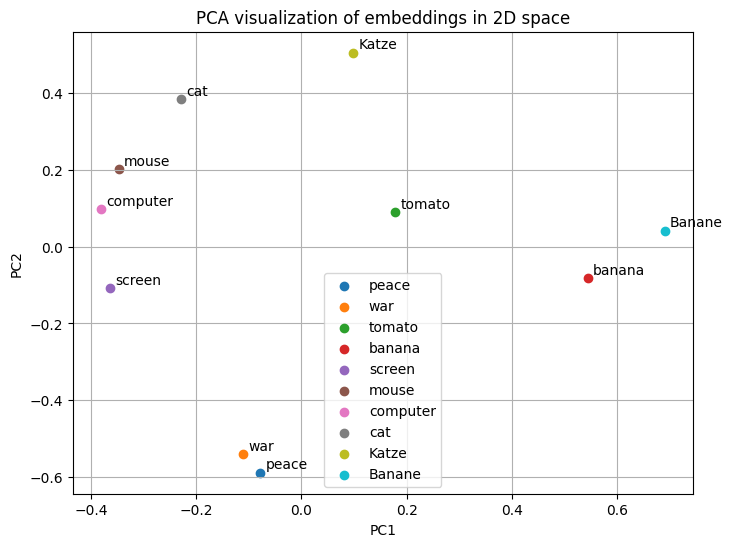

In [34]:
# @title Run PCA on customized word list
words = ['peace', 'war', 'tomato', 'banana', 'screen', 'mouse', 'computer', 'cat', 'Katze', 'Banane']
embed_words_and_plot_pca(words)

In [23]:
# @title Interactive Word Embedding Visualizer (Gradio App)
# prompt: Can you generate a gradio app with the code above, where a user can just enter words, and they will be embedded and visualized

!pip install gradio

import gradio as gr
import numpy as np
from sklearn.metrics.pairwise import cosine_distances
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import openai
from openai import OpenAI
from google.colab import userdata

# Create
client = OpenAI(api_key=userdata.get('OPENAI_API_KEY'))


def embed_words_and_visualize(words_str):
    """
    Embeds a list of words using an OpenAI model and plots a PCA visualization of the embeddings in 2D space.

    Parameters:
    words_str (str): A string containing words separated by spaces.

    Returns:
    str: Path to the generated plot image.
    """
    words = words_str.split()
    embeddings = []
    for word in words:
        embedding = get_embedding(" "+word, model='text-embedding-3-large')
        embeddings.append(embedding)

    embeddings_array = np.array(embeddings)
    pca = PCA(n_components=2)
    embeddings_2d = pca.fit_transform(embeddings_array)

    plt.figure(figsize=(8, 6))
    for i, emb in enumerate(embeddings_2d):
        plt.scatter(emb[0], emb[1], label=words[i])
        plt.text(emb[0] + 0.01, emb[1] + 0.01, words[i])

    plt.xlabel('PC1')
    plt.ylabel('PC2')
    plt.title('PCA visualization of embeddings in 2D space')
    plt.legend()
    plt.grid(True)
    plt.savefig('plot.png')  # Save the plot to a file
    plt.close()
    return 'plot.png'

# Create the Gradio interface
demo = gr.Interface(
    fn=embed_words_and_visualize,
    inputs=gr.Textbox(lines=5, placeholder="Enter words separated by spaces"),
    outputs="image",
    title="Word Embedding Visualization",
    description="Enter words and see their embeddings visualized in 2D space."
)

# Launch the interface
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://3a4404e26ca0f2a97a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Word Are Not Tokens

In [35]:
# @title Function: Fetch embedding along with token segments
import tiktoken
def get_embedding_with_tokens(word, model="text-embedding-3-large", prefix=" "):
    """
    Gets the embedding and returns the decoded subwords/tokens.
    """
    word = prefix + word
    response = client.embeddings.create(input=word, model=model)
    embedding = response.data[0].embedding

    tokenizer = tiktoken.encoding_for_model(model)
    tokens = tokenizer.encode(word)
    decoded_tokens = [tokenizer.decode([token]) for token in tokens]

    return { "tokens": decoded_tokens, "embedding": embedding}

In [36]:
# @title Analyze subwords for 'Banane'
get_embedding_with_tokens("Banane", prefix="")

{'tokens': ['Ban', 'ane'],
 'embedding': [-0.009490966796875,
  -0.005657196044921875,
  -0.0083160400390625,
  0.037506103515625,
  -0.052154541015625,
  -0.0014829635620117188,
  -0.00693511962890625,
  0.0166778564453125,
  -0.00848388671875,
  0.006076812744140625,
  -0.00952911376953125,
  0.016632080078125,
  -0.0294036865234375,
  -0.01210784912109375,
  -0.0271759033203125,
  -0.008026123046875,
  0.035888671875,
  -0.0060577392578125,
  -0.01776123046875,
  -0.002750396728515625,
  8.487701416015625e-05,
  -0.0249481201171875,
  0.032562255859375,
  -0.03900146484375,
  0.004344940185546875,
  0.0152587890625,
  0.0194244384765625,
  0.01471710205078125,
  -0.0283660888671875,
  0.002185821533203125,
  -0.01384735107421875,
  -0.025238037109375,
  -0.0242156982421875,
  -0.002559661865234375,
  -0.0206756591796875,
  0.01947021484375,
  0.00852203369140625,
  -0.01837158203125,
  -0.00844573974609375,
  -0.016357421875,
  0.002834320068359375,
  -0.01407623291015625,
  -0.0276

In [37]:
# @title Analyze subwords for German 'GEFÜHL'
result = get_embedding_with_tokens("GEFÜHL", prefix=" ")
print(f"Tokens: {result['tokens']}\nEmbedding sample (first 5 values): {result['embedding'][:5]}")

Tokens: [' G', 'EF', 'Ü', 'HL']
Embedding sample (first 5 values): [-0.00537109375, 0.0205230712890625, -0.004558563232421875, 0.0056915283203125, 0.00213623046875]


In [38]:
# @title Function: Get Cosine Similarity between two words
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

def get_vector_similarity(word1, word2, model="text-embedding-3-large"):
  embedding1 = get_embedding(word1, model=model)
  embedding2 = get_embedding(word2, model=model)
  similarity = cosine_similarity([embedding1], [embedding2])[0][0]
  return similarity

In [39]:
# @title Test similarity: German 'Katze' and 'Katzen'
get_vector_similarity("Katze", "Katzen")

np.float64(0.8473149195463121)

## Word A is to word B as word C to word D

In [40]:
# @title Function: Vector Analogy Solver
import numpy as np
def find_analogous_word(word_a, word_b, word_c, words_list, model="text-embedding-3-large"):
    embedding_a = get_embedding(word_a, model=model)
    embedding_b = get_embedding(word_b, model=model)
    embedding_c = get_embedding(word_c, model=model)

    diff_ab = np.array(embedding_b) - np.array(embedding_a)

    best_word = None
    best_similarity = -float('inf')
    for word in words_list:
        embedding_word = get_embedding(word, model=model)
        similarity = cosine_similarity([np.array(embedding_c) + diff_ab], [embedding_word])[0][0]
        if similarity > best_similarity:
            best_similarity = similarity
            best_word = word

    return best_word

In [41]:
# @title Run classic Analogy: Man is to King as Woman is to ...
find_analogous_word("man", "king", "woman", ["queen", "princess", "prince", "queens"])

'queen'

In [24]:
# @title Interactive Word Analogy Game (Gradio App)
# prompt: Create a gradio app for the analogy game, also draw all words in an PCA embedding space (2D). Also draw a line of the transition in the embedding space.

import numpy as np
from sklearn.metrics.pairwise import cosine_distances
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import openai
from openai import OpenAI
from google.colab import userdata
import gradio as gr
import tiktoken
from sklearn.metrics.pairwise import cosine_similarity

# Create
client = OpenAI(api_key=userdata.get('OPENAI_API_KEY'))

def get_embedding(word, model="text-embedding-3-small"):
   """
   Gets the embedding for a given word using the specified OpenAI model.

   Parameters:
   word (str): The word to embed.
   model (str): The name of the OpenAI model to use for embedding.

   Returns:
   list: The embedding for the word.
   """
   # Add a space before the word to ensure it's treated as a single word
   return client.embeddings.create(input = [" " + word], model=model).data[0].embedding


def find_analogous_word_and_visualize(word_a, word_b, word_c, words_list, model="text-embedding-3-large"):
    """
    Finds the word most analogous to word_c in the context of the analogy word_a is to word_b and visualizes the embeddings.

    Args:
      word_a (str): The first word in the analogy.
      word_b (str): The second word in the analogy.
      word_c (str): The third word in the analogy.
      words_list (list): A list of candidate words to find the analogous word from.
      model (str): The OpenAI model to use for embedding.

    Returns:
      str: The word most analogous to word_c.
      str: Path to the generated plot image.
    """
    # Get embeddings for all words
    embedding_a = get_embedding(word_a, model=model)
    embedding_b = get_embedding(word_b, model=model)
    embedding_c = get_embedding(word_c, model=model)
    embeddings = [embedding_a, embedding_b, embedding_c]
    words = [word_a, word_b, word_c]

    # Calculate the difference between the embeddings of word_a and word_b
    diff_ab = np.array(embedding_b) - np.array(embedding_a)

    # Find the word in words_list that has the most similar embedding to word_c + diff_ab
    best_word = None
    best_similarity = -float('inf')
    words_list = words_list.split()
    for word in words_list:
        embedding_word = get_embedding(word, model=model)
        similarity = cosine_similarity([np.array(embedding_c) + diff_ab], [embedding_word])[0][0]
        if similarity > best_similarity:
            best_similarity = similarity
            best_word = word

    # Get embeddings for all words including the best word
    for word in words_list:
        embedding_word = get_embedding(word, model=model)
        embeddings.append(embedding_word)
        words.append(word)

    # Convert embeddings list to a NumPy array for PCA
    embeddings_array = np.array(embeddings)

    # PCA reduction to 2D for visualization
    pca = PCA(n_components=2)
    embeddings_2d = pca.fit_transform(embeddings_array)

    # Plotting the 2D embeddings
    plt.figure(figsize=(8, 6))
    for i, emb in enumerate(embeddings_2d):
        plt.scatter(emb[0], emb[1], label=words[i])
        plt.text(emb[0] + 0.01, emb[1] + 0.01, words[i])

    # Draw a line between word_a, word_b, and word_c + diff_ab
    a_index = words.index(word_a)
    b_index = words.index(word_b)
    c_index = words.index(word_c)
    best_word_index = words.index(best_word)
    plt.plot([embeddings_2d[a_index][0], embeddings_2d[b_index][0]], [embeddings_2d[a_index][1], embeddings_2d[b_index][1]], color='red')
    plt.plot([embeddings_2d[c_index][0], embeddings_2d[best_word_index][0]], [embeddings_2d[c_index][1], embeddings_2d[best_word_index][1]], color='blue')

    plt.xlabel('PC1')
    plt.ylabel('PC2')
    plt.title('PCA visualization of embeddings in 2D space')
    plt.legend()
    plt.grid(True)
    plt.savefig('plot.png')  # Save the plot to a file
    plt.close()

    return best_word, 'plot.png'


# Create the Gradio interface
demo = gr.Interface(
    fn=find_analogous_word_and_visualize,
    inputs=[
        gr.Textbox("man",lines=1, placeholder="Word A"),
        gr.Textbox("king",lines=1, placeholder="Word B"),
        gr.Textbox("woman",lines=1, placeholder="Word C"),
        gr.Textbox("prince princess woman aunt uncle",lines=5, placeholder="Candidate words (separated by spaces)")
    ],
    outputs=[
        gr.Textbox(label="Most Analogous Word"),
        "image"
    ],
    title="Word Analogy Game",
    description="Find the most analogous word based on the given analogy."
)

# Launch the interface
demo.launch(share=True,debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://b74340feec0d887998.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
